# BC3409 BC3415 - Image Classification Workshop
## W6-01 CNN (Plain Vanilla) Pneumonia - v003

**Option 2:** configure and deploy the `WS_Colab_Image` CNN notebook on the Pneumonia chest X-ray data.
Judged on **data pre-processing** and **F1 score**.

**Approach.** The CNN from `v002` is kept unchanged. It is first run exactly as supplied (the *before*), then trained
again on properly pre-processed data (the *after*). Because the model is identical, the difference in F1 comes
from the data pre-processing. Both are scored on the same official test set of 624 images, which takes no part in any
decision.

### Result (official test set, 624 images)

| | F1 (pneumonia) | macro-F1 | accuracy | healthy children correctly cleared | test errors |
|---|---|---|---|---|---|
| **Before**: `v002` as supplied | 0.830 | 0.661 | 0.745 | 77 / 234 | 159 |
| **After**: same CNN, pre-processed data | **0.867** | **0.770** | **0.811** | **121 / 234** | **118** |

Same network, same test images: **41 fewer mistakes (-26%)**. Most of the gain is on healthy (NORMAL) children,
whom the original notebook mostly labelled as pneumonia.

| Section | Content |
|---|---|
| 1 | Setup (Colab or local) |
| 2 | Getting the data |
| 3 | Data audit: what is wrong with the data as supplied |
| 4 | Before: the `v002` notebook, as supplied |
| 5 | Pre-processing pipeline |
| 6 | After: the same CNN on pre-processed data |
| 7 | Decision threshold (validation only) |
| 8 | Test-set comparison: before vs after |
| 9 | Deployment |
| 10 | Limitations |

---
## 1. Setup
Runs in **Google Colab** or **locally**. About 10 minutes on a laptop CPU; faster on a Colab GPU.

In [1]:
import sys, os
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    !pip -q install kagglehub
print('Colab' if IN_COLAB else 'Local', '| Python', sys.version.split()[0])

Local | Python 3.13.15


In [2]:
import re, json, time, hashlib, random, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D, Input

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (f1_score, accuracy_score, recall_score, precision_score, roc_auc_score,
                             confusion_matrix, classification_report)

warnings.filterwarnings('ignore')
SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); keras.utils.set_random_seed(s)
set_seed()

IMG_SIZE = 150        # same as v002
b        = 20         # batch size, same as v002
EPOCHS   = 30         # same as v002
CLASSES  = ['NORMAL', 'PNEUMONIA']    # PNEUMONIA = positive class for F1

# QUICK_TEST=1 runs everything on a small subset for 1 epoch, to check the pipeline end-to-end.
QUICK_TEST = os.environ.get('QUICK_TEST') == '1'
if QUICK_TEST:
    EPOCHS = 1
print('TensorFlow', tf.__version__, '| Keras', keras.__version__,
      '| GPU:', tf.config.list_physical_devices('GPU') or 'none')

TensorFlow 2.21.0 | Keras 3.15.1 | GPU: none


---
## 2. Getting the data

Kaggle: [paultimothymooney/chest-xray-pneumonia](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia).
The loader looks for:
1. the `v002` Google Drive folder `/content/drive/MyDrive/AI4AnF/Data/Pneumonia` (mount Drive first),
2. a local `data/chest_xray` folder.

If neither exists, it downloads the dataset with `kagglehub`. No Kaggle account is needed.

The Kaggle zip contains a second, nested copy of the whole dataset (`chest_xray/chest_xray/`) plus macOS
`__MACOSX` files. Both are ignored.

In [3]:
def is_root(p):
    return p.is_dir() and all((p / s / c).is_dir() for s in ('train', 'test') for c in CLASSES)

def find_dataset():
    for c in [Path('/content/drive/MyDrive/AI4AnF/Data/Pneumonia'), Path('data/chest_xray'),
              Path('../data/chest_xray'), Path('chest_xray')]:
        if is_root(c):
            return c
    import kagglehub
    base = Path(kagglehub.dataset_download('paultimothymooney/chest-xray-pneumonia'))
    roots = [p.parent for p in base.rglob('train') if '__MACOSX' not in p.parts and is_root(p.parent)]
    return min(roots, key=lambda p: len(p.parts))     # outer copy, not chest_xray/chest_xray

ROOT = find_dataset()
print('Dataset:', ROOT.resolve())

Dataset: C:\Users\user.MYLNB2402\Work\BC3415\Week 8 Image\data\chest_xray


---
## 3. Data audit
Look at the data before deciding how to pre-process it.

In [4]:
rows = []
for split in ('train', 'val', 'test'):
    for y, cls in enumerate(CLASSES):
        for f in sorted((ROOT / split / cls).iterdir()):
            if f.suffix.lower() in ('.jpeg', '.jpg', '.png'):
                rows.append(dict(path=str(f), file=f.name, split=split, cls=cls, y=y))
df = pd.DataFrame(rows)

# patient ID from the file name: person123_bacteria_456.jpeg / IM-0115-0001.jpeg / NORMAL2-IM-1427-0001.jpeg
def patient(name, cls):
    m = re.match(r'(person\d+)_', name) if cls == 'PNEUMONIA' else re.match(r'((?:NORMAL2-)?IM-\d+)-', name)
    return cls[0] + ':' + (m.group(1) if m else name)
df['patient'] = [patient(n, c) for n, c in zip(df.file, df.cls)]

counts = df.pivot_table(index='split', columns='cls', values='file', aggfunc='count').loc[['train', 'val', 'test']]
counts['total'] = counts.sum(axis=1)
counts['% pneumonia'] = (100 * counts.PNEUMONIA / counts.total).round(1)
counts['patients'] = df.groupby('split').patient.nunique()
counts

cls,NORMAL,PNEUMONIA,total,% pneumonia,patients
split,,,,,
train,1341,3875,5216,74.3,2846
val,8,8,16,50.0,15
test,234,390,624,62.5,427


In [5]:
def meta(p):
    with Image.open(p) as im:
        return im.size[0], im.size[1], im.mode
df[['w', 'h', 'mode']] = pd.DataFrame([meta(p) for p in df.path], index=df.index)
df['aspect'] = (df.w / df.h).round(2)
df['md5'] = [hashlib.md5(open(p, 'rb').read()).hexdigest() for p in df.path]

print('colour modes stored:', df['mode'].value_counts().to_dict())
print('exact duplicate images:', df.duplicated('md5').sum())
print('\nmedian size by class:')
print(df.groupby('cls')[['w', 'h', 'aspect']].median())
print('\nhow well does image SHAPE alone (no pixels) predict the class? ROC-AUC =',
      round(roc_auc_score(df.y, df.aspect), 3))

colour modes stored: {'L': 5573, 'RGB': 283}
exact duplicate images: 32

median size by class:
                w       h  aspect
cls                              
NORMAL     1654.0  1323.0    1.23
PNEUMONIA  1160.0   776.0    1.49

how well does image SHAPE alone (no pixels) predict the class? ROC-AUC = 0.84


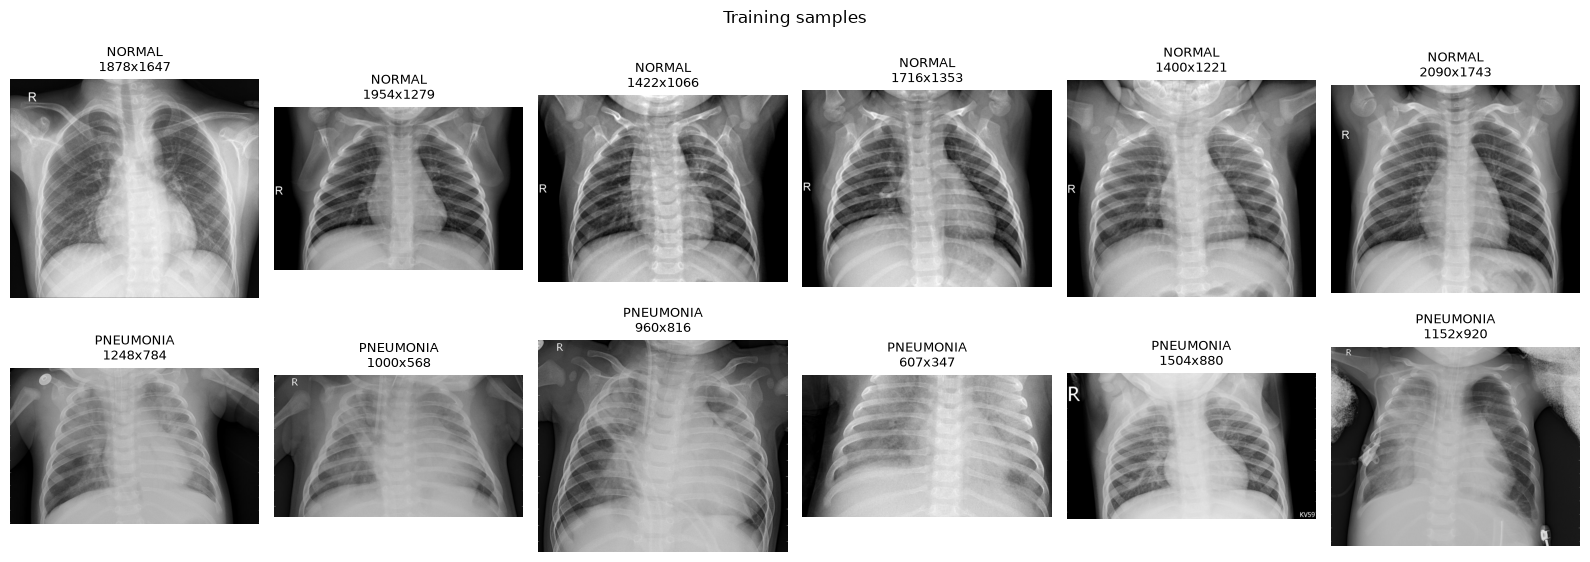

In [6]:
fig, ax = plt.subplots(2, 6, figsize=(16, 6))
for r, cls in enumerate(CLASSES):
    for a, (_, row) in zip(ax[r], df[(df.split == 'train') & (df.cls == cls)].sample(6, random_state=1).iterrows()):
        a.imshow(Image.open(row.path).convert('L'), cmap='gray'); a.axis('off')
        a.set_title(f'{cls}\n{row.w}x{row.h}', fontsize=9)
plt.suptitle('Training samples'); plt.tight_layout(); plt.show()

### What the audit shows
1. **The `val` folder has only 16 images** (8 + 8). Validation accuracy can only move in steps of 6.25 points, so it
   cannot be used to pick a model, an epoch or a threshold.
2. **Class imbalance**: 74% of training images are PNEUMONIA, but only 62.5% of the test set. A model that leans
   towards PNEUMONIA looks good in training and then flags healthy test children.
3. **Mixed colour modes**: 283 files are stored as RGB, the rest as greyscale. They are all greyscale X-rays.
4. **32 exact duplicate files** (byte-identical), 26 of them in `train`/`val`.
5. **Image shape gives away the class.** PNEUMONIA films are smaller and wider (median 1160x776, aspect 1.49) than
   NORMAL ones (1654x1323, aspect 1.23). The aspect ratio alone, with no pixels at all, separates the classes with
   ROC-AUC 0.84. Squashing every film to 150x150, as `v002` does, distorts the two classes differently and hands
   the network this shortcut.
6. **Several images per patient**: 5,216 training images come from 2,846 patients (up to 30 images each). A random
   split would put the same child in both training and validation and overstate the validation score.

(The file names reuse the same patient numbers in `train` and `test`, but looking at the images shows they are
different children; there are no byte-identical files across the two. The official test set is therefore treated as
independent.)

---
## 4. Before: the `v002` notebook, as supplied

Same settings as `W6-01 CNN (Plain Vanilla) Pneumonia v002`: raw 0-255 pixels, 150x150 RGB, batch 20, the same CNN,
the 16-image `val` folder, 30 epochs, and the weights from the last epoch.

**Configuration fix (needed to run it at all):** `v002` loads images with `ImageDataGenerator`, which was removed
in Keras 3. Current Colab ships Keras 3, so the import fails. The drop-in replacement is
`keras.utils.image_dataset_from_directory`. With no options it does the same thing: raw 0-255 RGB pixels and
one-hot labels. The decoded images are cached in memory so the 30 epochs run faster; this does not change the
data the model sees.

In [7]:
set_seed()
def load_dir(split):
    return keras.utils.image_dataset_from_directory(str(ROOT / split), label_mode='categorical', class_names=CLASSES,
                                                    image_size=(150, 150), batch_size=b, shuffle=False)
train_data, val_data, test_data = load_dir('train'), load_dir('val'), load_dir('test')
n_train = sum(1 for _ in train_data.unbatch())
train_data = train_data.unbatch().cache().shuffle(n_train, seed=SEED).batch(b)    # shuffle=True, as in v002
if QUICK_TEST:
    train_data = train_data.take(5)

def build_v002(channels=3, rescale=False):
    # the v002 CNN, unchanged (rescale=True only adds the 0-1 pixel scaling in front, step P6)
    model = Sequential()
    model.add(Input((150, 150, channels)))
    if rescale:
        model.add(layers.Rescaling(1 / 255.))
    model.add(Conv2D(32, (3, 3), activation='relu'))
    model.add(MaxPooling2D(pool_size=(2, 2), strides=2))
    model.add(Dropout(0.05))
    model.add(Conv2D(32, (3, 3), activation='relu'))
    model.add(MaxPooling2D(pool_size=(2, 2), strides=2))
    model.add(Dropout(0.05))
    model.add(Conv2D(16, (3, 3), activation='relu'))
    model.add(MaxPooling2D(pool_size=(2, 2), strides=2))
    model.add(Dropout(0.05))
    model.add(Flatten())
    model.add(Dense(16, activation='relu'))
    model.add(Dense(2, activation='softmax'))
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

model = build_v002()
model.summary()
t0 = time.time()
h = model.fit(train_data, epochs=EPOCHS, validation_data=val_data, verbose=2)
print(f'training time: {(time.time() - t0) / 60:.1f} min')

Found 5216 files belonging to 2 classes.


Found 16 files belonging to 2 classes.


Found 624 files belonging to 2 classes.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 36, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 17, 17, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4624)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │        74,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

...

Epoch 29/30


261/261 - 20s - 77ms/step - accuracy: 0.9795 - loss: 0.0692 - val_accuracy: 0.8125 - val_loss: 0.3271


Epoch 30/30


261/261 - 23s - 90ms/step - accuracy: 0.9864 - loss: 0.0361 - val_accuracy: 0.9375 - val_loss: 0.1674


training time: 10.3 min


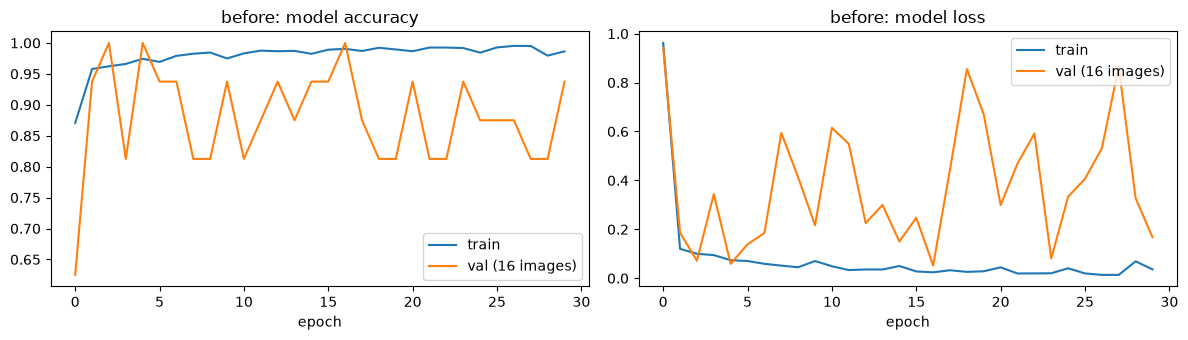

              precision    recall  f1-score   support

      NORMAL     0.9747    0.3291    0.4920       234
   PNEUMONIA     0.7119    0.9949    0.8299       390

    accuracy                         0.7452       624
   macro avg     0.8433    0.6620    0.6610       624
weighted avg     0.8105    0.7452    0.7032       624

val accuracy only ever took the values [np.float64(0.625), np.float64(0.8125), np.float64(0.875), np.float64(0.9375), np.float64(1.0)]


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for k, a in zip(['accuracy', 'loss'], ax):
    a.plot(h.history[k]); a.plot(h.history['val_' + k])
    a.set_title('before: model ' + k); a.set_xlabel('epoch'); a.legend(['train', 'val (16 images)'])
plt.tight_layout(); plt.show()

p_before = model.predict(test_data, verbose=0)[:, 1]
y_test = np.concatenate([y.numpy().argmax(1) for _, y in test_data])
pred_before = (p_before >= 0.5).astype(int)          # = np.argmax(pred, axis=1) in v002
print(classification_report(y_test, pred_before, target_names=CLASSES, digits=4))
print('val accuracy only ever took the values', sorted(set(np.round(h.history['val_accuracy'], 4))))

**What the *before* result shows:**
- The validation curve is noise: on 16 images its accuracy swings between 62.5% and 100% from one epoch to the next.
- Training accuracy reaches 99% while the model clears only **77 of 234 healthy children** (NORMAL recall 0.33).
  It has learned to answer PNEUMONIA almost every time.
- Its F1 of 0.830 looks reasonable only because most test images are PNEUMONIA. A "model" that answers PNEUMONIA
  for every image would score F1 = 0.769 (precision 0.625, recall 1.0). The macro-F1 of 0.661 shows the real problem.

---
## 5. Pre-processing pipeline

| Step | What | Why |
|---|---|---|
| P1 | **Remove exact duplicate images** | a duplicate in both training and validation inflates the validation score |
| P2 | **New validation set**: merge `train` + `val`, then hold out 1/7 (about 14%) of *patients* (stratified, grouped by patient) | the 16-image `val` folder is too small to choose a model or threshold with. Grouping by patient keeps all of one child's X-rays on the same side, so the score is honest |
| P3 | **Greyscale** (1 channel instead of 3) | X-rays have one channel; 283 files are stored as RGB with three identical copies of it |
| P4 | **Centre crop to square**, then resize to 150x150 | the original squashes every film into a square. PNEUMONIA films are wider than NORMAL ones, so they were distorted differently, and the shape itself gave away the class (Section 3). Cropping makes every image the same shape without distortion |
| P5 | **CLAHE** contrast enhancement (applied at full resolution) | X-ray exposure varies a lot between machines; CLAHE (Contrast-Limited Adaptive Histogram Equalisation) brings out lung texture in dark or washed-out films |
| P6 | **Scale pixels to 0-1** | `v002` fed raw 0-255 values; neural networks train much more reliably on small, consistent inputs |
| P7 | **Augmentation** (training images only): small rotation, zoom, shift, contrast. **No flips** | adds variety in patient positioning and exposure; a mirrored X-ray would put the heart on the wrong side |
| P8 | **Class weights** | 74% of training images are PNEUMONIA; weights stop the model winning by simply guessing PNEUMONIA |

The **test set is not used in any of these decisions**. It only goes through the fixed image steps (P3-P6).

In [9]:
# P1 + P2: remove duplicates, then a patient-grouped, stratified train/validation split
dev = df[df.split.isin(['train', 'val'])]
n_before = len(dev)
dev = dev.drop_duplicates('md5').reset_index(drop=True)
test_df = df[df.split == 'test'].reset_index(drop=True)
print(f'P1: removed {n_before - len(dev)} duplicate images')

tr, va = next(StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED).split(dev, dev.y, groups=dev.patient))
train_df, val_df = dev.iloc[tr].reset_index(drop=True), dev.iloc[va].reset_index(drop=True)
assert not set(train_df.patient) & set(val_df.patient)        # no patient on both sides
if QUICK_TEST:
    train_df, val_df, test_df = [pd.concat([d[d.y == k].head(60) for k in (0, 1)]).reset_index(drop=True)
                                 for d in (train_df, val_df, test_df)]

pd.DataFrame({n: [len(d), d.patient.nunique(), round(100 * d.y.mean(), 1)]
              for n, d in [('train', train_df), ('validation', val_df), ('test', test_df)]},
             index=['images', 'patients', '% pneumonia']).T

P1: removed 26 duplicate images


,images,patients,% pneumonia
train,4462.0,2453.0,74.1
validation,744.0,408.0,74.1
test,624.0,427.0,62.5


pre-processed 5830 images in 27s


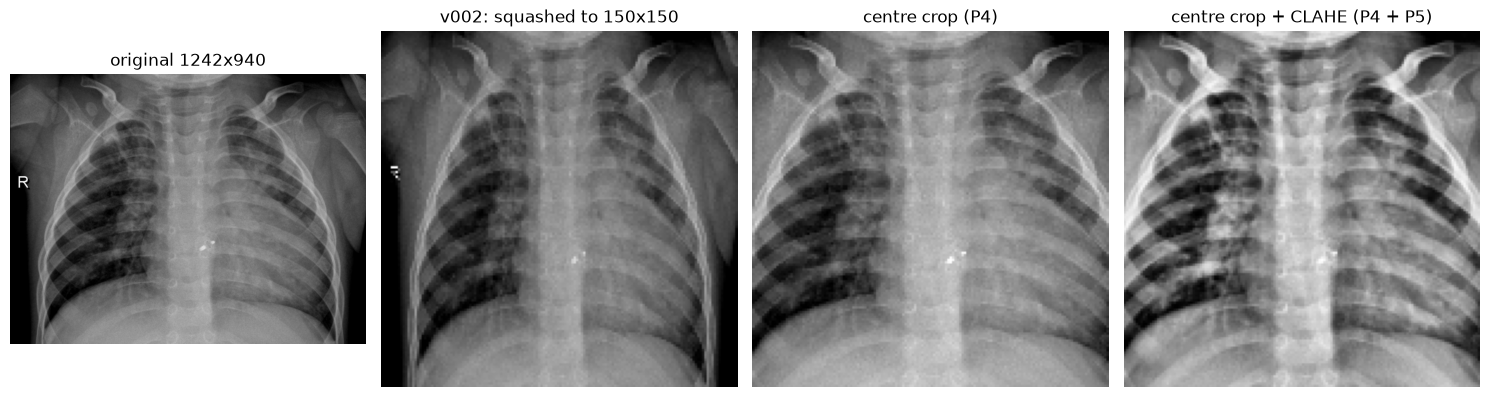

In [10]:
# P3 + P4 + P5: greyscale -> CLAHE -> centre crop -> resize
def preprocess(path, size=IMG_SIZE):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)                             # P3
    img = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(img)          # P5
    h, w = img.shape; s = min(h, w)
    img = img[(h - s) // 2:(h - s) // 2 + s, (w - s) // 2:(w - s) // 2 + s]       # P4 crop
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)            # P4 resize

def load_all(paths):
    with ThreadPoolExecutor(8) as ex:
        return np.stack(list(ex.map(preprocess, paths)))[..., None]              # (n, 150, 150, 1) uint8

t0 = time.time()
X_tr, X_va, X_te = load_all(train_df.path), load_all(val_df.path), load_all(test_df.path)
y_tr, y_va, y_te = train_df.y.values, val_df.y.values, test_df.y.values
print(f'pre-processed {len(X_tr) + len(X_va) + len(X_te)} images in {time.time() - t0:.0f}s')

# what each step does to one image
i = int(np.where(y_tr == 1)[0][3])
orig = cv2.imread(train_df.path[i], cv2.IMREAD_GRAYSCALE)
fig, ax = plt.subplots(1, 4, figsize=(15, 4))
ax[0].imshow(orig, cmap='gray'); ax[0].set_title(f'original {orig.shape[1]}x{orig.shape[0]}')
ax[1].imshow(cv2.resize(orig, (150, 150)), cmap='gray'); ax[1].set_title('v002: squashed to 150x150')
h_, w_ = orig.shape; s_ = min(h_, w_)
ax[2].imshow(cv2.resize(orig[(h_ - s_) // 2:(h_ - s_) // 2 + s_, (w_ - s_) // 2:(w_ - s_) // 2 + s_], (150, 150)), cmap='gray')
ax[2].set_title('centre crop (P4)')
ax[3].imshow(X_tr[i, ..., 0], cmap='gray'); ax[3].set_title('centre crop + CLAHE (P4 + P5)')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

class weights: {'NORMAL': np.float64(1.93), 'PNEUMONIA': np.float64(0.67)}


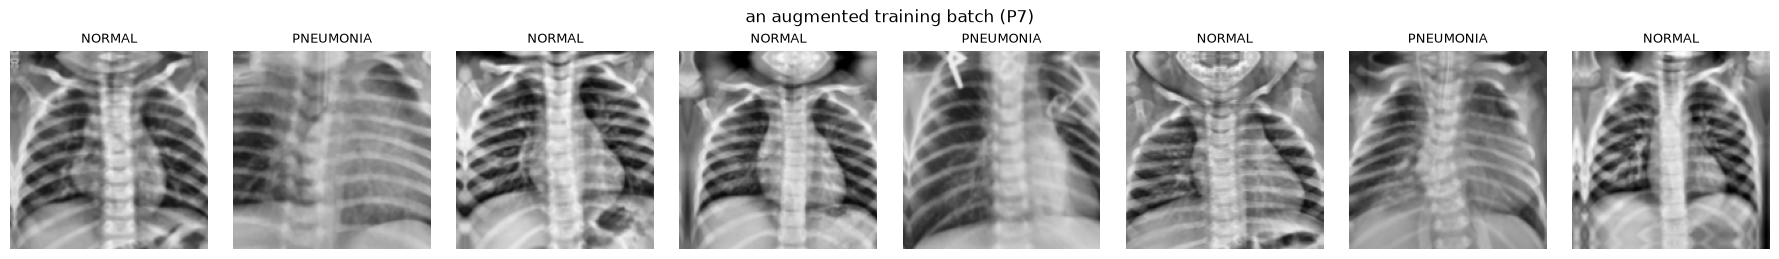

In [11]:
# P6 scaling (inside the model), P7 augmentation, P8 class weights
augment = keras.Sequential([layers.RandomRotation(5 / 360), layers.RandomZoom(0.1),
                            layers.RandomTranslation(0.05, 0.05), layers.RandomContrast(0.1)])

def make_ds(X, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X, keras.utils.to_categorical(y, 2)))
    if training:
        ds = ds.shuffle(len(X), seed=SEED)
    ds = ds.batch(b).map(lambda x, y: (tf.cast(x, tf.float32), y))
    if training:
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

ds_tr, ds_va, ds_te = make_ds(X_tr, y_tr, training=True), make_ds(X_va, y_va), make_ds(X_te, y_te)

w = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_tr)
class_weight = {0: w[0], 1: w[1]}
print('class weights:', {CLASSES[k]: round(v, 2) for k, v in class_weight.items()})

xb, yb = next(iter(ds_tr))
fig, ax = plt.subplots(1, 8, figsize=(18, 2.6))
for a, im, yv in zip(ax, xb.numpy(), yb.numpy()):
    a.imshow(im[..., 0], cmap='gray', vmin=0, vmax=255); a.set_title(CLASSES[int(yv.argmax())], fontsize=9); a.axis('off')
plt.suptitle('an augmented training batch (P7)'); plt.tight_layout(); plt.show()

---
## 6. After: the same CNN on pre-processed data

The network layers are **exactly the `v002` CNN**. Only three things differ, all on the data side:
- the input is **1 channel** (greyscale) instead of 3; this only changes the size of the first layer's filters,
- a `Rescaling(1/255)` layer puts the 0-1 pixel scaling (P6) inside the model, so the saved model takes raw images,
- training **keeps the epoch with the best validation loss** (on the new validation set of about 750 images) instead of the last
  epoch. This is only possible because P2 created a usable validation set.

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 148, 148, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 72, 72, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 36, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 36, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 34, 34, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 17, 17, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 17, 17, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4624)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │        74,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 88,226 (344.63 KB)

 Trainable params: 88,226 (344.63 KB)

 Non-trainable params: 0 (0.00 B)

...

Epoch 8/30


224/224 - 39s - 172ms/step - accuracy: 0.9415 - loss: 0.1463 - val_accuracy: 0.9274 - val_loss: 0.1775


Epoch 9/30


224/224 - 21s - 94ms/step - accuracy: 0.9446 - loss: 0.1432 - val_accuracy: 0.9462 - val_loss: 0.1316


training time: 4.2 min | best epoch: 3


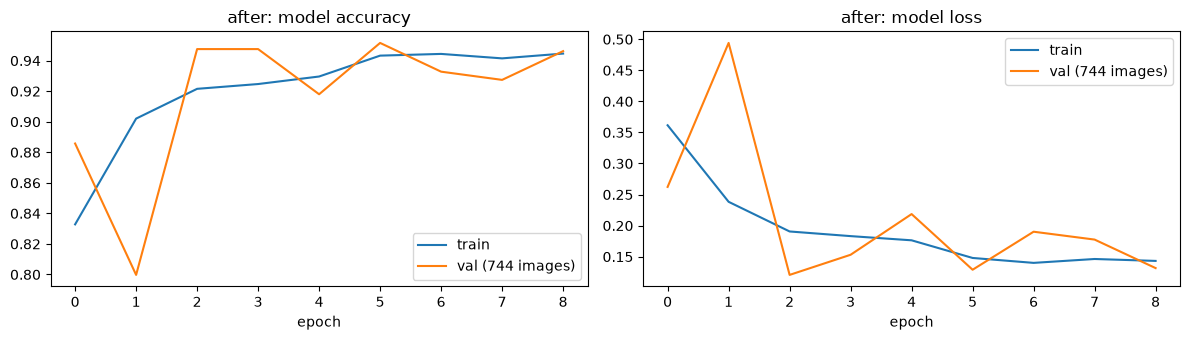

In [12]:
set_seed()
model2 = build_v002(channels=1, rescale=True)
model2.summary()

ckpt = Path('best_model.keras')
t0 = time.time()
h2 = model2.fit(ds_tr, epochs=EPOCHS, validation_data=ds_va, class_weight=class_weight, verbose=2,
                callbacks=[keras.callbacks.ModelCheckpoint(str(ckpt), monitor='val_loss', save_best_only=True),
                           keras.callbacks.EarlyStopping(monitor='val_loss', patience=6)])
model2 = keras.models.load_model(ckpt)
print(f'training time: {(time.time() - t0) / 60:.1f} min | best epoch: {int(np.argmin(h2.history["val_loss"])) + 1}')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for k, a in zip(['accuracy', 'loss'], ax):
    a.plot(h2.history[k]); a.plot(h2.history['val_' + k])
    a.set_title('after: model ' + k); a.set_xlabel('epoch'); a.legend(['train', f'val ({len(X_va)} images)'])
plt.tight_layout(); plt.show()

---
## 7. Decision threshold (validation only)

`v002` predicts PNEUMONIA when its probability is at least 0.5 (`argmax`). That cut-off is a convention, not a
rule. Here the threshold is chosen on the **validation set** to maximise macro-F1, which weighs mistakes on
healthy and sick children equally. The test set is not used.

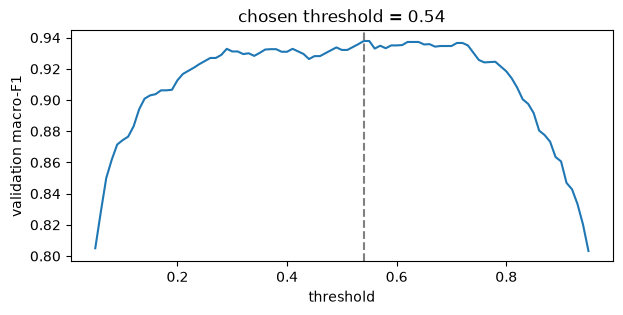

validation macro-F1: 0.9321 at 0.5 -> 0.9379 at 0.54


In [13]:
p_val = model2.predict(ds_va, verbose=0)[:, 1]
grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
f1s = [f1_score(y_va, (p_val >= t).astype(int), average='macro') for t in grid]
THRESHOLD = float(grid[int(np.argmax(f1s))])

plt.figure(figsize=(7, 3)); plt.plot(grid, f1s); plt.axvline(THRESHOLD, ls='--', c='grey')
plt.xlabel('threshold'); plt.ylabel('validation macro-F1'); plt.title(f'chosen threshold = {THRESHOLD}'); plt.show()
print(f'validation macro-F1: {f1_score(y_va, (p_val >= .5).astype(int), average="macro"):.4f} at 0.5 -> '
      f'{max(f1s):.4f} at {THRESHOLD}')

---
## 8. Test-set comparison: before vs after
The same 624 test images, scored once.

In [14]:
p_after = model2.predict(ds_te, verbose=0)[:, 1]
# align the before-model's predictions (directory order) with test_df order
key = lambda paths: [Path(p).parent.name + '/' + Path(p).name for p in paths]
p_before_aligned = pd.Series(p_before, index=key(test_data.file_paths)).loc[key(test_df.path)].values

def scores(y, p, t):
    yhat = (p >= t).astype(int)
    return {'F1 (pneumonia)': f1_score(y, yhat), 'macro-F1': f1_score(y, yhat, average='macro'),
            'accuracy': accuracy_score(y, yhat), 'precision (pneumonia)': precision_score(y, yhat),
            'recall (pneumonia)': recall_score(y, yhat), 'recall (normal)': recall_score(y, yhat, pos_label=0),
            'errors': int((yhat != y).sum())}

results = pd.DataFrame({'before (v002)': scores(y_te, p_before_aligned, 0.5),
                        'after, threshold 0.5': scores(y_te, p_after, 0.5),
                        f'after, threshold {THRESHOLD} (final)': scores(y_te, p_after, THRESHOLD)}).T
results.round(4)

,F1 (pneumonia),macro-F1,accuracy,precision (pneumonia),recall (pneumonia),recall (normal),errors
before (v002),0.8299,0.6610,0.7452,0.7119,0.9949,0.3291,159.0
"after, threshold 0.5",0.8635,0.7595,0.8045,0.7659,0.9897,0.4957,122.0
"after, threshold 0.54 (final)",0.8671,0.7697,0.8109,0.7731,0.9872,0.5171,118.0


AFTER (final):
               precision    recall  f1-score   support

      NORMAL     0.9603    0.5171    0.6722       234
   PNEUMONIA     0.7731    0.9872    0.8671       390

    accuracy                         0.8109       624
   macro avg     0.8667    0.7521    0.7697       624
weighted avg     0.8433    0.8109    0.7940       624



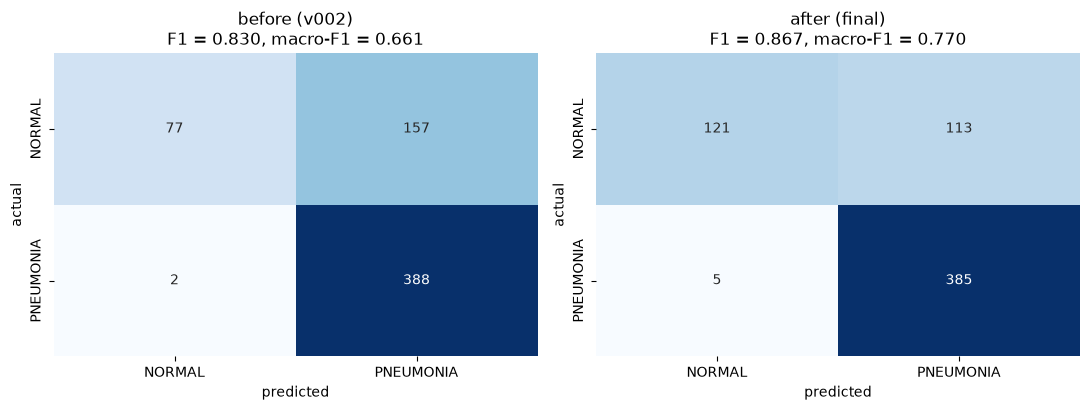

In [15]:
pred_after = (p_after >= THRESHOLD).astype(int)
print('AFTER (final):\n', classification_report(y_te, pred_after, target_names=CLASSES, digits=4))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, (name, yh) in zip(ax, [('before (v002)', (p_before_aligned >= .5).astype(int)), ('after (final)', pred_after)]):
    sns.heatmap(confusion_matrix(y_te, yh), annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=a)
    a.set_title(f'{name}\nF1 = {f1_score(y_te, yh):.3f}, macro-F1 = {f1_score(y_te, yh, average="macro"):.3f}')
    a.set_xlabel('predicted'); a.set_ylabel('actual')
plt.tight_layout(); plt.show()

**Reading the comparison:**
- **F1 (pneumonia) 0.830 -> 0.867, macro-F1 0.661 -> 0.770, errors 159 -> 118**, with the same network.
- Healthy children correctly cleared rise from **77 to 121** (NORMAL recall 0.33 -> 0.52), while pneumonia recall
  stays at about 99% (388 -> 385 of 390 found). Fewer false alarms, almost no extra missed cases.
- Tuning the threshold on validation (0.54 instead of 0.5) adds only 4 fewer errors; almost all of the gain comes
  from the pre-processing and from keeping the best epoch.
- The remaining errors are almost all false alarms (113 of 118 are healthy children called PNEUMONIA). See
  Limitations.

---
## 9. Deployment

The model is saved together with its settings, so a new X-ray goes through exactly the same pre-processing:
- `deploy/pneumonia_cnn.keras`: the trained network (includes the 0-1 scaling)
- `deploy/pneumonia_config.json`: image size, CLAHE settings, decision threshold, class names

`predict_xray()` below is the whole inference path. `predict.py` in the submission folder is the same code as a
command-line tool and an optional Gradio web app.

In [16]:
DEPLOY = Path('deploy'); DEPLOY.mkdir(exist_ok=True)
model2.save(DEPLOY / 'pneumonia_cnn.keras')
config = {'model': 'pneumonia_cnn.keras', 'img_size': IMG_SIZE, 'geometry': 'centre_crop',
          'clahe': {'clipLimit': 2.0, 'tileGridSize': [8, 8]}, 'threshold': THRESHOLD, 'classes': CLASSES,
          'test_metrics': {k: round(float(v), 4) for k, v in scores(y_te, p_after, THRESHOLD).items()}}
(DEPLOY / 'pneumonia_config.json').write_text(json.dumps(config, indent=2))
print(json.dumps(config, indent=2))

{
  "model": "pneumonia_cnn.keras",
  "img_size": 150,
  "geometry": "centre_crop",
  "clahe": {
    "clipLimit": 2.0,
    "tileGridSize": [
      8,
      8
    ]
  },
  "threshold": 0.54,
  "classes": [
    "NORMAL",
    "PNEUMONIA"
  ],
  "test_metrics": {
    "F1 (pneumonia)": 0.8671,
    "macro-F1": 0.7697,
    "accuracy": 0.8109,
    "precision (pneumonia)": 0.7731,
    "recall (pneumonia)": 0.9872,
    "recall (normal)": 0.5171,
    "errors": 118.0
  }
}


In [17]:
def predict_xray(path, model, cfg):
    x = preprocess(path, cfg['img_size'])[None, ..., None].astype('float32')
    p = float(model.predict(x, verbose=0)[0, 1])
    return {'prediction': cfg['classes'][int(p >= cfg['threshold'])], 'p_pneumonia': round(p, 4)}

deployed = keras.models.load_model(DEPLOY / 'pneumonia_cnn.keras')
cfg = json.loads((DEPLOY / 'pneumonia_config.json').read_text())
for i in [0, 1, len(test_df) - 2, len(test_df) - 1]:
    print(f'{test_df.file[i]:32s} actual {test_df.cls[i]:9s} ->', predict_xray(test_df.path[i], deployed, cfg))
assert abs(predict_xray(test_df.path[0], deployed, cfg)['p_pneumonia'] - p_after[0]) < 1e-3
print('reloaded model reproduces the notebook predictions')

IM-0001-0001.jpeg                actual NORMAL    -> {'prediction': 'PNEUMONIA', 'p_pneumonia': 0.6538}
IM-0003-0001.jpeg                actual NORMAL    -> {'prediction': 'NORMAL', 'p_pneumonia': 0.4488}
person99_bacteria_473.jpeg       actual PNEUMONIA -> {'prediction': 'PNEUMONIA', 'p_pneumonia': 0.9902}


person99_bacteria_474.jpeg       actual PNEUMONIA -> {'prediction': 'PNEUMONIA', 'p_pneumonia': 0.9962}
reloaded model reproduces the notebook predictions


In [18]:
# Optional web demo: set RUN_GRADIO = True (Colab prints a public link)
RUN_GRADIO = False
if RUN_GRADIO:
    !pip -q install gradio
    import gradio as gr
    def ui(path):
        p = predict_xray(path, deployed, cfg)['p_pneumonia']
        return {'PNEUMONIA': p, 'NORMAL': 1 - p}
    gr.Interface(ui, gr.Image(type='filepath'), gr.Label(), title='Pneumonia X-ray classifier (coursework demo)'
                 ).launch(share=IN_COLAB)

---
## 10. Limitations
- **Validation is much easier than test.** On the new validation set the model reaches macro-F1 0.94; on the test set
  it reaches 0.77. Validation comes from the same pool of images as training, while the test images, especially the
  NORMAL ones, differ in ways the pre-processing cannot fully remove. This is why a threshold tuned on validation
  only partly transfers, and it is a known property of this Kaggle dataset.
- **One training run each.** No repeated seeds, so the after-scores could move by about a point on a re-run. The
  before/after gap (41 errors) is much larger than that.
- **Steps are not scored one by one.** All pre-processing steps are applied together, to keep the run to about 15
  minutes on a laptop CPU. Measuring each step separately would need one training run per step.
- **The data are paediatric chest X-rays from one source.** The model should not be expected to work on adults or on
  other hospitals' equipment.
- Coursework only: **not for clinical use**.
- The submitted run was executed locally (Windows, CPU, TensorFlow 2.21 / Keras 3.15). In Colab the numbers will differ
  slightly because GPU training is not bit-for-bit deterministic.

---
### The End, is the New Start.